# 03 · Análisis bivariado y perfilado

Comparamos los hábitos y antecedentes con `G3`, la nota final, en cada asignatura. Las diferencias entre grupos son descriptivas: no prueban que una variable cause la otra.

## 1. Librerías y lectura de datos

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

raiz = Path.cwd()
if not (raiz / 'datos').is_dir():
    raiz = raiz.parent
if not (raiz / 'datos').is_dir():
    raise FileNotFoundError('Abre el proyecto o la carpeta notebooks antes de ejecutar.')
resultados = raiz / 'resultados'
resultados.mkdir(exist_ok=True)
fuentes = {'matematicas': 'student-mat.csv', 'portugues': 'student-por.csv'}
datos = {nombre: pd.read_csv(raiz / 'datos' / archivo, sep=';')
         for nombre, archivo in fuentes.items()}
import matplotlib.pyplot as plt
import seaborn as sns
import contextlib
import io
import warnings
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='IProgress not found.*')
    warnings.filterwarnings('ignore', category=DeprecationWarning)
    from ydata_profiling import ProfileReport
sns.set_theme(style='whitegrid', palette='deep')


## 2. Tiempo de estudio y nota final
Cada barra muestra la nota media y el número de registros del grupo.


MATEMATICAS · nota final por tiempo de estudio


,Registros,Nota media,Mediana
studytime,,,
<2 h,105,10.048,10.0
2–5 h,198,10.172,11.0
5–10 h,65,11.400,12.0
>10 h,27,11.259,12.0


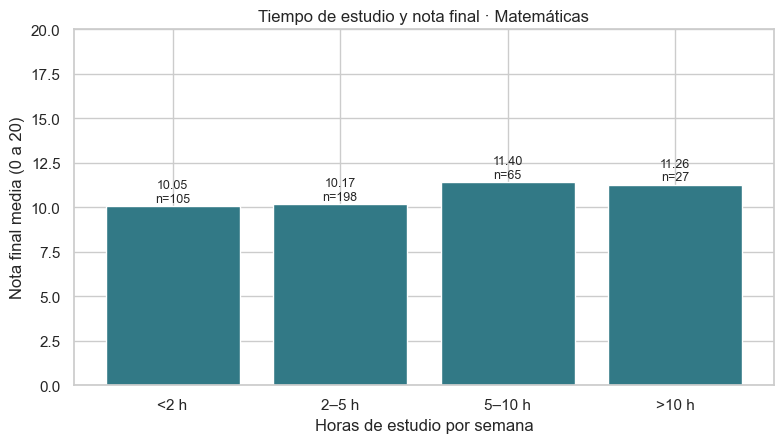


PORTUGUES · nota final por tiempo de estudio


,Registros,Nota media,Mediana
studytime,,,
<2 h,212,10.844,11.0
2–5 h,305,12.092,12.0
5–10 h,97,13.227,13.0
>10 h,35,13.057,13.0


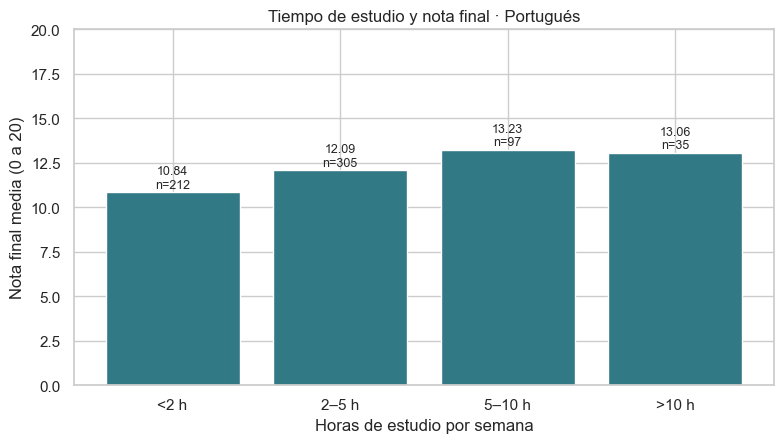

In [2]:
intervalos = {1: '<2 h', 2: '2–5 h', 3: '5–10 h', 4: '>10 h'}
variables = ['studytime', 'goout', 'Dalc', 'Walc', 'absences', 'failures']
for nombre, df in datos.items():
    print(f'\n{nombre.upper()} · nota final por tiempo de estudio')
    resumen = df.groupby('studytime')['G3'].agg(['count', 'mean', 'median']).round(3)
    display(resumen.rename(index=intervalos, columns={'count': 'Registros', 'mean': 'Nota media', 'median': 'Mediana'}))
    fig, ax = plt.subplots(figsize=(8, 4.6))
    bars = ax.bar([intervalos[i] for i in resumen.index], resumen['mean'], color='#327986')
    for bar, (_, fila) in zip(bars, resumen.iterrows()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.25,
                f"{fila['mean']:.2f}\nn={int(fila['count'])}", ha='center', fontsize=9)
    asignatura = {'matematicas': 'Matemáticas', 'portugues': 'Portugués'}[nombre]
    ax.set(title=f'Tiempo de estudio y nota final · {asignatura}',
           xlabel='Horas de estudio por semana', ylabel='Nota final media (0 a 20)', ylim=(0, 20))
    fig.tight_layout()
    fig.savefig(resultados / f'habitos_{nombre}.png', dpi=160, bbox_inches='tight')
    plt.show()


En ambas materias el grupo de 5 a 10 horas presenta un promedio superior al de menos de 2 horas. El grupo de más de 10 horas es más pequeño, por lo que su media debe interpretarse con cuidado.

## 3. Comparaciones por hábitos y antecedentes


MATEMATICAS · correlación de Spearman con G3


,Correlación
studytime,0.105
goout,-0.166
Dalc,-0.121
Walc,-0.104
absences,0.018
failures,-0.361


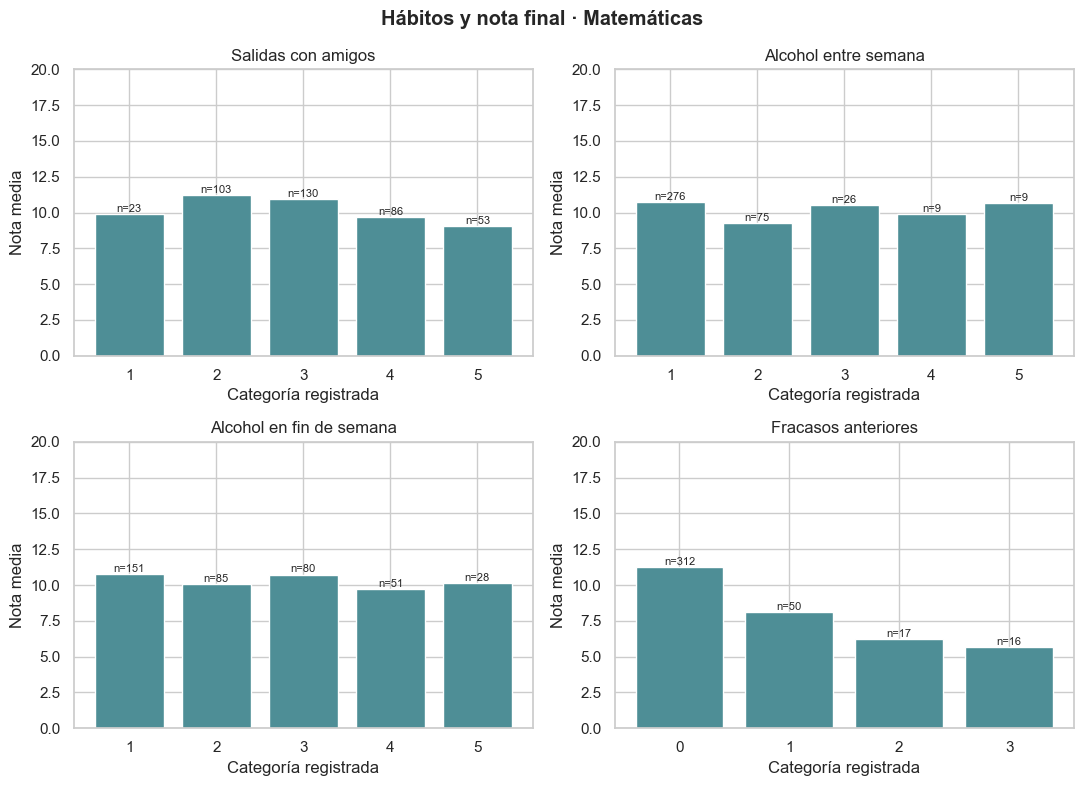


PORTUGUES · correlación de Spearman con G3


,Correlación
studytime,0.275
goout,-0.105
Dalc,-0.208
Walc,-0.171
absences,-0.159
failures,-0.448


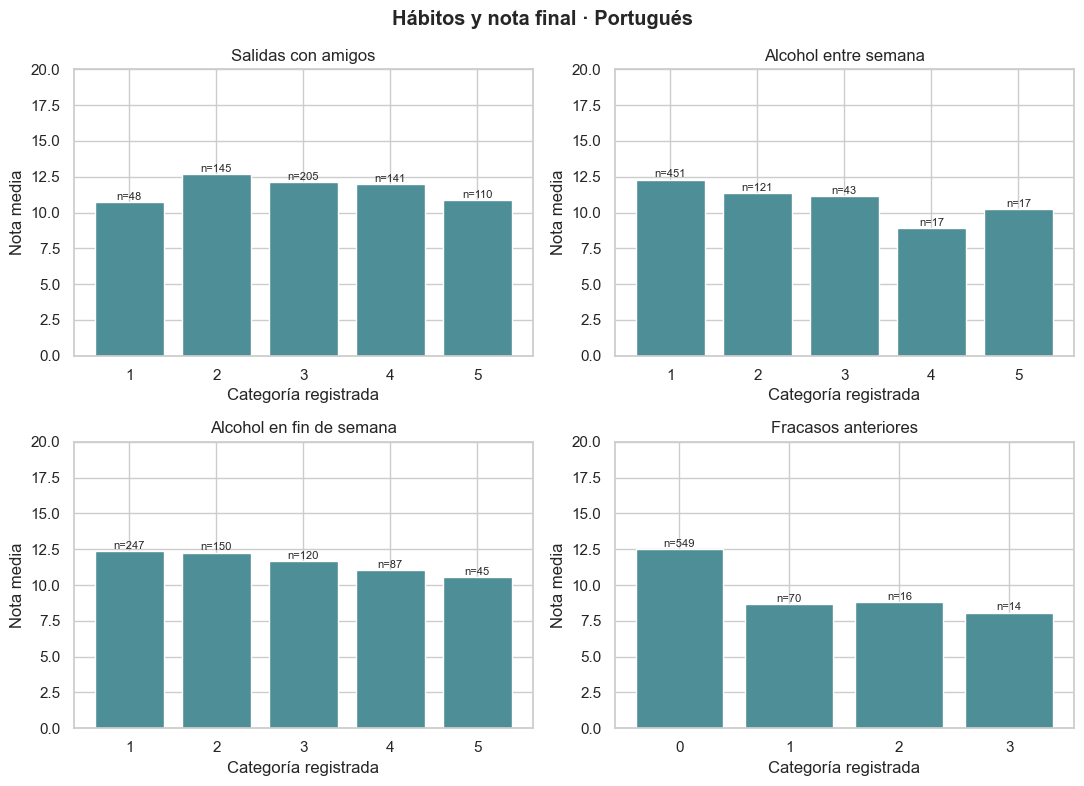

In [3]:
titulos = {'goout': 'Salidas con amigos', 'Dalc': 'Alcohol entre semana',
           'Walc': 'Alcohol en fin de semana', 'failures': 'Fracasos anteriores'}
for nombre, df in datos.items():
    print(f'\n{nombre.upper()} · correlación de Spearman con G3')
    display(df[variables + ['G3']].corr(method='spearman')['G3'].drop('G3').round(3).to_frame('Correlación'))
    for variable in variables:
        resumen = df.groupby(variable)['G3'].agg(['count', 'mean', 'median']).round(3)
        resumen.to_csv(resultados / f'{nombre}_{variable}_y_G3.csv', encoding='utf-8')
    fig, ejes = plt.subplots(2, 2, figsize=(11, 8))
    for ax, (variable, titulo) in zip(ejes.flat, titulos.items()):
        resumen = df.groupby(variable)['G3'].agg(['count', 'mean'])
        barras = ax.bar(resumen.index.astype(str), resumen['mean'], color='#4e8e96')
        for barra, cantidad in zip(barras, resumen['count']):
            ax.text(barra.get_x() + barra.get_width()/2, barra.get_height() + 0.15,
                    f'n={cantidad}', ha='center', fontsize=8)
        ax.set(title=titulo, xlabel='Categoría registrada', ylabel='Nota media', ylim=(0, 20))
    asignatura = {'matematicas': 'Matemáticas', 'portugues': 'Portugués'}[nombre]
    fig.suptitle(f'Hábitos y nota final · {asignatura}', fontweight='bold')
    fig.tight_layout()
    fig.savefig(resultados / f'comparaciones_{nombre}.png', dpi=150, bbox_inches='tight')
    plt.show()


Las correlaciones y promedios orientan la lectura, pero no explican por sí solos las diferencias. Las categorías con pocos registros pueden tener promedios menos estables.

## 4. Ausencias agrupadas y nota final

Comparamos intervalos de ausencias, con la cantidad de registros, la media y la mediana de la nota final. Esta agrupación reproduce la comparación del informe.

In [4]:
for nombre, df in datos.items():
    grupos = pd.cut(df['absences'], bins=[-1, 0, 4, 9, float('inf')],
                    labels=['0', '1–4', '5–9', '10 o más'])
    grupos.name = 'ausencias'
    resumen = df.groupby(grupos, observed=False)['G3'].agg(['count', 'mean', 'median']).round(3)
    resumen.to_csv(resultados / f'{nombre}_ausencias_agrupadas.csv', encoding='utf-8')
    print(f'\n{nombre.upper()} · nota final por grupo de ausencias')
    display(resumen.rename(columns={'count': 'Registros', 'mean': 'Nota media', 'median': 'Mediana'}))



MATEMATICAS · nota final por grupo de ausencias


,Registros,Nota media,Mediana
ausencias,,,
0,115,8.443,10.0
1–4,129,11.651,11.0
5–9,68,11.456,11.0
10 o más,83,10.373,10.0



PORTUGUES · nota final por grupo de ausencias


,Registros,Nota media,Mediana
ausencias,,,
0,244,12.041,13.0
1–4,222,12.072,12.0
5–9,113,11.770,11.0
10 o más,70,11.129,11.0


Las diferencias entre grupos son descriptivas. En particular, una nota media baja en el grupo sin ausencias no demuestra que faltar mejore las notas.

## 5. Perfilado automático con ydata_profiling
Se genera un perfil HTML por asignatura con las 33 variables originales.

In [5]:
for nombre, df in datos.items():
    ruta = resultados / f'perfil_{nombre}.html'
    with contextlib.redirect_stderr(io.StringIO()):
        ProfileReport(df, title=f'Perfil de datos: {nombre}', minimal=True, progress_bar=False).to_file(ruta)
    print(f'Perfil generado: {ruta.name} · {len(df)} registros y {len(df.columns)} variables')


Perfil generado: perfil_matematicas.html · 395 registros y 33 variables


Perfil generado: perfil_portugues.html · 649 registros y 33 variables


Los perfiles complementan la revisión con pandas. Los ceros en ausencias y fracasos representan valores posibles, por lo que una alerta no implica que deban eliminarse.